In [1]:
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [10]:
# level 1: 
level_1_scores = {
    "EnzyMind": {
        "Enzyme Check": [1.00, 1.00, 0.97],
        "Sequence Query": [1.00, 1.00, 1.00],
        "Catalytic Reaction Query": [1.00, 1.00, 0.85],
        "Kinetic Parameter Query": [1.00, 1.00, 1.00],
        "Active Site Query": [1.00, 0.98, 1.00],
    },
    "GPT-5.2": {
        "Enzyme Check": [1.00, 0.77, 0.82],
        "Sequence Query": [0.97, 0.18, 0.43],
        "Catalytic Reaction Query": [1.00, 0.37, 0.48],
        "Kinetic Parameter Query": [0.98, 0.48, 0.48],
        "Active Site Query": [0.80, 0.08, 0.08],
    },
    "DeepSeek-V3.2": {
        "Enzyme Check": [1.00, 0.27, 0.97],
        "Sequence Query": [0.97, 0.00, 0.47],
        "Catalytic Reaction Query": [1.00, 0.00, 0.10],
        "Kinetic Parameter Query": [0.38, 0.00, 0.00],
        "Active Site Query": [0.817, 0.00, 0.00],
    }
}

In [11]:
systems = ["EnzyMind", "GPT-5.2", "DeepSeek-V3.2"]
tasks = ["Enzyme Check", "Sequence Query", "Catalytic Reaction Query", "Kinetic Parameter Query", "Active Site Query"]

level_1_data = []
for system in systems:
    row = []
    for task in tasks:
        row.extend(level_1_scores[system][task])
    level_1_data.append(row)

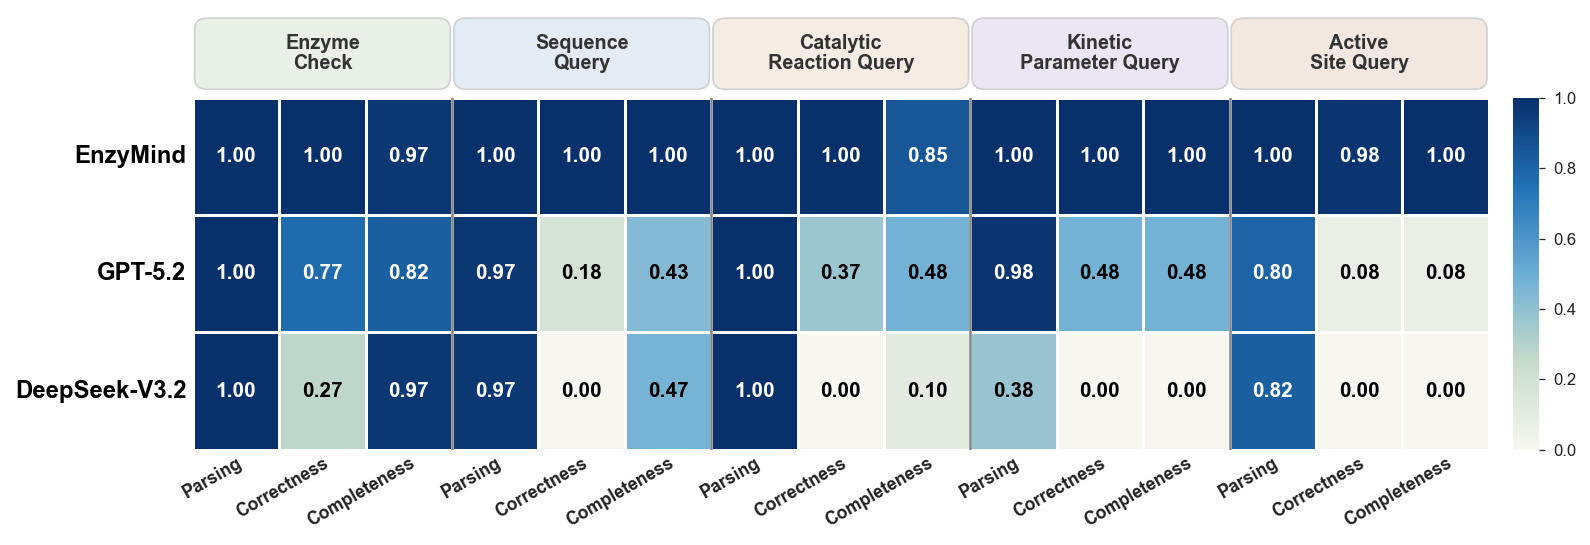

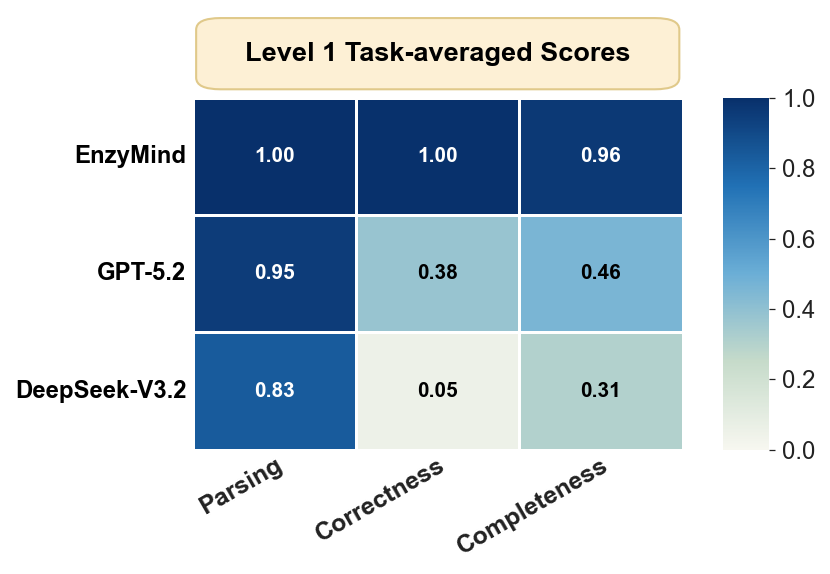

In [12]:

from matplotlib.patches import FancyBboxPatch

# ===== 1. 主热图数据 =====
index = ["EnzyMind", "GPT-5.2", "DeepSeek-V3.2"]

metric_labels = ["Parsing", "Correctness", "Completeness"]
columns = metric_labels * 5

df = pd.DataFrame(level_1_data, index=index, columns=columns)

# ===== 2. 右侧 summary strip =====
summary_df = pd.DataFrame({
    "Parsing": df.iloc[:, [0, 3, 6, 9, 12]].mean(axis=1),
    "Correctness": df.iloc[:, [1, 4, 7, 10, 13]].mean(axis=1),
    "Completeness": df.iloc[:, [2, 5, 8, 11, 14]].mean(axis=1),
}, index=index)

# ===== 3. 视觉风格 (Nature subjournal style) =====
BG         = "#ffffff"
CELL_BG    = "#ffffff"
DARK       = "#000000"
LABEL_CLR  = "#222222"
GRID_CLR   = "#ffffff"
SUMMARY_BG = "#fdf0d5"
SUMMARY_EDGE = "#e0c98a"
SUMMARY_TEXT = "#6b5318"

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica Neue", "DejaVu Sans"],
    "mathtext.fontset": "stixsans",
    "axes.unicode_minus": False,
})

sns.set_theme(
    style="white",
    font_scale=1.0,
    rc={
        "figure.facecolor": BG,
        "axes.facecolor": BG,
        "axes.edgecolor": "#cccccc",
        "figure.dpi": 150,
    },
)

cmap = mcolors.LinearSegmentedColormap.from_list(
    "nature_heat",
    ["#f7f7f0", "#c6dbca", "#6baed6", "#2171b5", "#08306b"],
    N=256,
)

group_specs = [
    (0,  3,  "Enzyme\nCheck",       "#e8f0e8"),
    (3,  6,  "Sequence\nQuery",     "#e3ecf5"),
    (6,  9,  "Catalytic\nReaction Query", "#f5ece3"),
    (9,  12, "Kinetic\nParameter Query",  "#ece5f3"),
    (12, 15, "Active\nSite Query",        "#f3e8e0"),
]

# ===== 4A. 左图：主热图 =====
fig = plt.figure(figsize=(10.2, 4.2), facecolor=BG, constrained_layout=False)
gs = fig.add_gridspec(
    nrows=2, ncols=3,
    height_ratios=[0.22, 1],
    width_ratios=[15, 0.08, 0.30],
    hspace=0.025,
    wspace=0.02,
    left=0.08, right=0.96,
    top=0.82, bottom=0.13,
)

ax_top = fig.add_subplot(gs[0, 0])
ax_main = fig.add_subplot(gs[1, 0])
cbar_ax = fig.add_subplot(gs[1, 2])

ax_top.set_xlim(0, df.shape[1])
ax_top.set_ylim(0, 1)
for start, end, label, color in group_specs:
    fancy = FancyBboxPatch(
        (start + 0.08, 0.10), end - start - 0.16, 0.80,
        boxstyle="round,pad=0.06,rounding_size=0.15",
        facecolor=color, edgecolor="#d0d0d0", linewidth=0.8,
        transform=ax_top.transData, zorder=2,
    )
    ax_top.add_patch(fancy)
    ax_top.text(
        (start + end) / 2, 0.50, label,
        ha="center", va="center",
        fontsize=9.5, fontweight="bold", color="#333333",
        linespacing=1.08, zorder=3,
    )
ax_top.axis("off")

sns.heatmap(
    df, ax=ax_main, cmap=cmap, vmin=0, vmax=1,
    annot=True, fmt=".2f",
    annot_kws={"fontsize": 10, "fontweight": "semibold"},
    linewidths=1.4, linecolor=GRID_CLR,
    cbar=True, cbar_ax=cbar_ax,
    square=False,
    yticklabels=index, xticklabels=columns,
    cbar_kws={"label": ""},
)

ax_main.set_xlabel("")
ax_main.set_ylabel("")
ax_main.set_facecolor(CELL_BG)
for spine in ax_main.spines.values():
    spine.set_visible(False)

ax_main.tick_params(axis="y", rotation=0, labelsize=11.5, pad=3, length=0)
for label in ax_main.get_yticklabels():
    label.set_fontweight("bold")
    label.set_color(DARK)

ax_main.tick_params(axis="x", rotation=30, labelsize=8.5, pad=2, length=0)
for label in ax_main.get_xticklabels():
    label.set_ha("right")
    label.set_rotation_mode("anchor")
    label.set_color(LABEL_CLR)
    label.set_fontweight("bold")

for x in [3, 6, 9, 12]:
    ax_main.axvline(x, color="#444444", linewidth=1.2, alpha=0.65)

for text in ax_main.texts:
    val = float(text.get_text())
    text.set_color("#ffffff" if val >= 0.50 else DARK)


cbar_ax.tick_params(labelsize=8, colors=LABEL_CLR, length=3, width=0.6)

cbar_ax.set_facecolor(BG)
for spine in cbar_ax.spines.values():
    spine.set_visible(False)
for label in cbar_ax.get_yticklabels():
    label.set_color(LABEL_CLR)

plt.savefig("level1_query_main_heatmap.svg", bbox_inches="tight", facecolor=BG)
plt.show()

# ===== 4B. 右图：Cross-task Mean =====
fig = plt.figure(figsize=(4.8, 4.2), facecolor=BG, constrained_layout=False)
gs = fig.add_gridspec(
    nrows=2, ncols=2,
    height_ratios=[0.22, 1],
    width_ratios=[3.4, 0.32],
    hspace=0.025,
    wspace=0.15,
    left=0.14, right=0.94,
    top=0.82, bottom=0.13,
)

ax_summary_top = fig.add_subplot(gs[0, 0])
ax_summary = fig.add_subplot(gs[1, 0])
cbar_ax_summary = fig.add_subplot(gs[1, 1])

ax_summary_top.set_xlim(0, summary_df.shape[1])
ax_summary_top.set_ylim(0, 1)
fancy_s = FancyBboxPatch(
    (0.08, 0.10), summary_df.shape[1] - 0.16, 0.80,
    boxstyle="round,pad=0.06,rounding_size=0.15",
    facecolor=SUMMARY_BG, edgecolor=SUMMARY_EDGE, linewidth=1.0,
    transform=ax_summary_top.transData, zorder=2,
)
ax_summary_top.add_patch(fancy_s)
ax_summary_top.text(
    summary_df.shape[1] / 2, 0.50, "Level 1 Task-averaged Scores",
    ha="center", va="center",
    fontsize=13, fontweight="bold", color=DARK,
    zorder=3,
)
ax_summary_top.axis("off")

sns.heatmap(
    summary_df, ax=ax_summary, cmap=cmap, vmin=0, vmax=1,
    annot=True, fmt=".2f",
    annot_kws={"fontsize": 10, "fontweight": "semibold"},
    linewidths=1.4, linecolor=GRID_CLR,
    cbar=True, cbar_ax=cbar_ax_summary,
    yticklabels=index, xticklabels=summary_df.columns,
    square=False,
    cbar_kws={"label": ""},
)

ax_summary.set_xlabel("")
ax_summary.set_ylabel("")
ax_summary.set_facecolor(CELL_BG)
for spine in ax_summary.spines.values():
    spine.set_visible(False)

ax_summary.tick_params(axis="y", rotation=0, labelsize=11.5, pad=3, length=0)
for label in ax_summary.get_yticklabels():
    label.set_fontweight("bold")
    label.set_color(DARK)

ax_summary.tick_params(axis="x", rotation=30, labelsize=12, pad=2, length=0)
for label in ax_summary.get_xticklabels():
    label.set_ha("right")
    label.set_rotation_mode("anchor")
    label.set_color(LABEL_CLR)
    label.set_fontweight("bold")

for text in ax_summary.texts:
    val = float(text.get_text())
    text.set_color("#ffffff" if val >= 0.50 else DARK)

cbar_ax_summary.tick_params(labelsize=11.5, colors=LABEL_CLR, length=3, width=0.6)

cbar_ax_summary.set_facecolor(BG)
for spine in cbar_ax_summary.spines.values():
    spine.set_visible(False)
for label in cbar_ax_summary.get_yticklabels():
    label.set_color(LABEL_CLR)

plt.savefig("level1_query_summary_heatmap.svg", bbox_inches="tight", facecolor=BG)
plt.show()


In [13]:
# level 2: 
level2_scores = {
    "EnzyMind": {
        "Enzyme Recognition": [1.00, 0.90, 1.0],
        "EC Number Prediction": [1.00, 0.933, 1.00],
        "Enzyme Type Recommend": [1.00, 0.7, 0.917],
        "Substrate Determination": [1.00, 0.93, 1.00],
        "Active Site Prediciton": [1.00, 0.68, 0.67],
    },
    "GPT-5.2": {
        "Enzyme Recognition": [0.90, 0.78, 0.98],
        "EC Number Prediction": [0.87, 0.03, 0.10],
        "Enzyme Type Recommend": [1.000, 0.417, 0.967],
        "Substrate Determination": [0.767, 0.100, 0.950],
        "Active Site Prediciton": [0.983, 0.333, 0.317],
    },
    "DeepSeek-V3.2": {
        "Enzyme Recognition": [0.583, 0.483, 0.567],
        "EC Number Prediction": [0.983, 0.033, 0.917],
        "Enzyme Type Recommend": [0.983, 0.250, 0.950],
        "Substrate Determination": [0.900, 0.467, 1.00],
        "Active Site Prediciton": [0.983, 0.017, 0.017],
    }
}

In [14]:
systems = ["EnzyMind", "GPT-5.2", "DeepSeek-V3.2"]
tasks = ["Enzyme Recognition", "EC Number Prediction", "Enzyme Type Recommend", "Substrate Determination", "Active Site Prediciton"]

level2_ = []
for system in systems:
    row = []
    for task in tasks:
        row.extend(level2_scores[system][task])
    level2_.append(row)

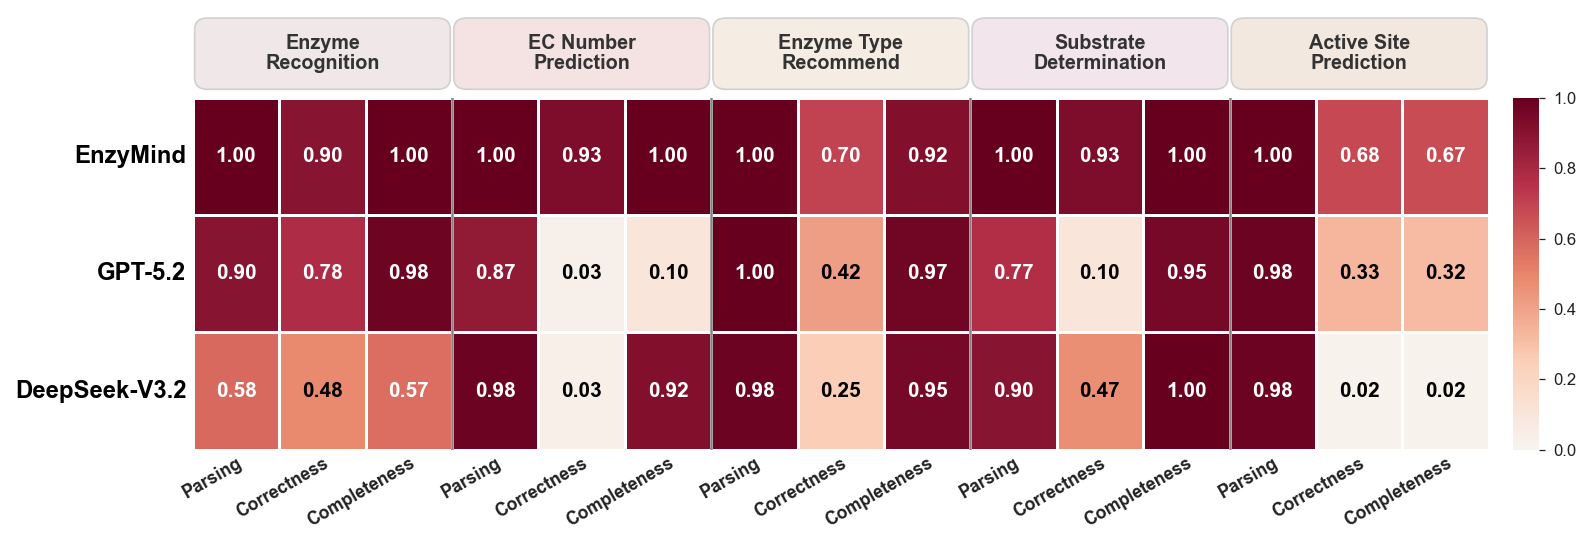

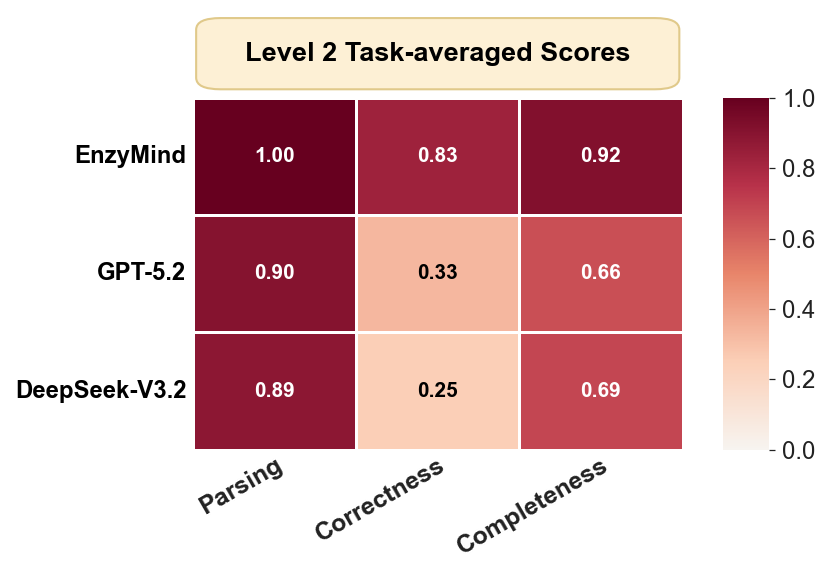

In [ ]:
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch

# ===== 1. 主热图数据 =====
index = ["EnzyMind", "GPT-5.2", "DeepSeek-V3.2"]

metric_labels = ["Parsing", "Correctness", "Completeness"]
columns = metric_labels * 5

df = pd.DataFrame(level2_, index=index, columns=columns)

# ===== 2. 右侧 summary strip =====
summary_df = pd.DataFrame({
    "Parsing": df.iloc[:, [0, 3, 6, 9, 12]].mean(axis=1),
    "Correctness": df.iloc[:, [1, 4, 7, 10, 13]].mean(axis=1),
    "Completeness": df.iloc[:, [2, 5, 8, 11, 14]].mean(axis=1),
}, index=index)

# ===== 3. 视觉风格 =====
BG         = "#ffffff"
CELL_BG    = "#ffffff"
DARK       = "#000000"
LABEL_CLR  = "#222222"
GRID_CLR   = "#ffffff"
SUMMARY_BG = "#fdf0d5"
SUMMARY_EDGE = "#e0c98a"
SUMMARY_TEXT = "#6b5318"

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica Neue", "DejaVu Sans"],
    "mathtext.fontset": "stixsans",
    "axes.unicode_minus": False,
})

sns.set_theme(
    style="white",
    font_scale=1.0,
    rc={
        "figure.facecolor": BG,
        "axes.facecolor": BG,
        "axes.edgecolor": "#cccccc",
        "figure.dpi": 150,
    },
)

cmap = mcolors.LinearSegmentedColormap.from_list(
    "nature_warm",
    ["#f7f4f0", "#fbcfb7", "#e8856a", "#b8324a", "#67001f"],
    N=256,
)

group_specs = [
    (0,  3,  "Enzyme\nRecognition",       "#f0e8e8"),
    (3,  6,  "EC Number\nPrediction",     "#f5e3e3"),
    (6,  9,  "Enzyme Type\nRecommend",    "#f5ece3"),
    (9,  12, "Substrate\nDetermination",  "#f3e5ec"),
    (12, 15, "Active Site\nPrediction",   "#f3e8e0"),
]

# ===== 4A. 左图：主热图 =====
fig = plt.figure(figsize=(10.2, 4.2), facecolor=BG, constrained_layout=False)
gs = fig.add_gridspec(
    nrows=2, ncols=3,
    height_ratios=[0.22, 1],
    width_ratios=[15, 0.08, 0.30],
    hspace=0.025,
    wspace=0.02,
    left=0.08, right=0.96,
    top=0.82, bottom=0.13,
)

ax_top = fig.add_subplot(gs[0, 0])
ax_main = fig.add_subplot(gs[1, 0])
cbar_ax = fig.add_subplot(gs[1, 2])

ax_top.set_xlim(0, df.shape[1])
ax_top.set_ylim(0, 1)
for start, end, label, color in group_specs:
    fancy = FancyBboxPatch(
        (start + 0.08, 0.10), end - start - 0.16, 0.80,
        boxstyle="round,pad=0.06,rounding_size=0.15",
        facecolor=color, edgecolor="#d0d0d0", linewidth=0.8,
        transform=ax_top.transData, zorder=2,
    )
    ax_top.add_patch(fancy)
    ax_top.text(
        (start + end) / 2, 0.50, label,
        ha="center", va="center",
        fontsize=9.5, fontweight="bold", color="#333333",
        linespacing=1.08, zorder=3,
    )
ax_top.axis("off")

sns.heatmap(
    df, ax=ax_main, cmap=cmap, vmin=0, vmax=1,
    annot=True, fmt=".2f",
    annot_kws={"fontsize": 10, "fontweight": "semibold"},
    linewidths=1.4, linecolor=GRID_CLR,
    cbar=True, cbar_ax=cbar_ax,
    square=False,
    yticklabels=index, xticklabels=columns,
    cbar_kws={"label": ""},
)

ax_main.set_xlabel("")
ax_main.set_ylabel("")
ax_main.set_facecolor(CELL_BG)
for spine in ax_main.spines.values():
    spine.set_visible(False)

ax_main.tick_params(axis="y", rotation=0, labelsize=11.5, pad=3, length=0)
for label in ax_main.get_yticklabels():
    label.set_fontweight("bold")
    label.set_color(DARK)

ax_main.tick_params(axis="x", rotation=30, labelsize=8.5, pad=2, length=0)
for label in ax_main.get_xticklabels():
    label.set_ha("right")
    label.set_rotation_mode("anchor")
    label.set_color(LABEL_CLR)
    label.set_fontweight("bold")

for x in [3, 6, 9, 12]:
    ax_main.axvline(x, color="#444444", linewidth=1.2, alpha=0.65)

for text in ax_main.texts:
    val = float(text.get_text())
    text.set_color("#ffffff" if val >= 0.50 else DARK)


cbar_ax.tick_params(labelsize=8, colors=LABEL_CLR, length=3, width=0.6)
cbar_ax.set_facecolor(BG)
for spine in cbar_ax.spines.values():
    spine.set_visible(False)
for label in cbar_ax.get_yticklabels():
    label.set_color(LABEL_CLR)

plt.savefig("level2_prediction_main_heatmap.svg", bbox_inches="tight", facecolor=BG)
plt.show()

# ===== 4B. 右图：Cross-task Mean =====
fig = plt.figure(figsize=(4.8, 4.2), facecolor=BG, constrained_layout=False)
gs = fig.add_gridspec(
    nrows=2, ncols=2,
    height_ratios=[0.22, 1],
    width_ratios=[3.4, 0.32],
    hspace=0.025,
    wspace=0.15,
    left=0.14, right=0.94,
    top=0.82, bottom=0.13,
)

ax_summary_top = fig.add_subplot(gs[0, 0])
ax_summary = fig.add_subplot(gs[1, 0])
cbar_ax_summary = fig.add_subplot(gs[1, 1])

ax_summary_top.set_xlim(0, summary_df.shape[1])
ax_summary_top.set_ylim(0, 1)
fancy_s = FancyBboxPatch(
    (0.08, 0.10), summary_df.shape[1] - 0.16, 0.80,
    boxstyle="round,pad=0.06,rounding_size=0.15",
    facecolor=SUMMARY_BG, edgecolor=SUMMARY_EDGE, linewidth=1.0,
    transform=ax_summary_top.transData, zorder=2,
)
ax_summary_top.add_patch(fancy_s)
ax_summary_top.text(
    summary_df.shape[1] / 2, 0.50, "Level 2 Task-averaged Scores",
    ha="center", va="center",
    fontsize=13, fontweight="bold", color=DARK,
    zorder=3,
)
ax_summary_top.axis("off")

sns.heatmap(
    summary_df, ax=ax_summary, cmap=cmap, vmin=0, vmax=1,
    annot=True, fmt=".2f",
    annot_kws={"fontsize": 10, "fontweight": "semibold"},
    linewidths=1.4, linecolor=GRID_CLR,
    cbar=True, cbar_ax=cbar_ax_summary,
    yticklabels=index, xticklabels=summary_df.columns,
    square=False,
    cbar_kws={"label": ""},
)

ax_summary.set_xlabel("")
ax_summary.set_ylabel("")
ax_summary.set_facecolor(CELL_BG)
for spine in ax_summary.spines.values():
    spine.set_visible(False)

ax_summary.tick_params(axis="y", rotation=0, labelsize=11.5, pad=3, length=0)
for label in ax_summary.get_yticklabels():
    label.set_fontweight("bold")
    label.set_color(DARK)

ax_summary.tick_params(axis="x", rotation=30, labelsize=12, pad=2, length=0)
for label in ax_summary.get_xticklabels():
    label.set_ha("right")
    label.set_rotation_mode("anchor")
    label.set_color(LABEL_CLR)
    label.set_fontweight("bold")

for text in ax_summary.texts:
    val = float(text.get_text())
    text.set_color("#ffffff" if val >= 0.50 else DARK)

cbar_ax_summary.tick_params(labelsize=11.5, colors=LABEL_CLR, length=3, width=0.6)

cbar_ax_summary.set_facecolor(BG)
for spine in cbar_ax_summary.spines.values():
    spine.set_visible(False)
for label in cbar_ax_summary.get_yticklabels():
    label.set_color(LABEL_CLR)

plt.savefig("level2_prediction_summary_heatmap.svg", bbox_inches="tight", facecolor=BG)
plt.show()

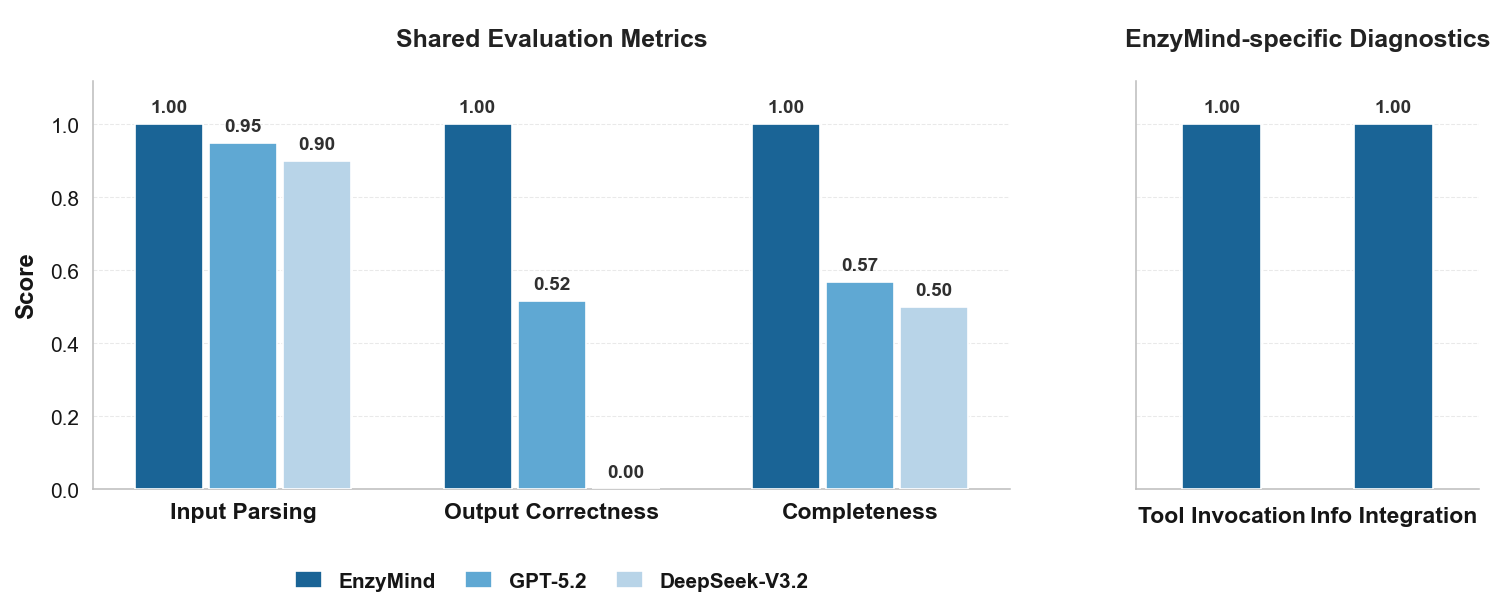

In [17]:

# =========================
# Data: Level 3
# =========================
methods = ["EnzyMind", "GPT-5.2", "DeepSeek-V3.2"]

shared_metrics = ["Input Parsing", "Output Correctness", "Completeness"]
shared_scores = {
    "EnzyMind":      [1.000, 1.000, 1.000],
    "GPT-5.2":       [0.950, 0.517, 0.567],
    "DeepSeek-V3.2": [0.900, 0.000, 0.500],
}

diag_metrics = ["Tool Invocation", "Info Integration"]
diag_scores  = [1.000, 1.000]

# =========================
# Style
# =========================
BG        = "#ffffff"
DARK      = "#000000"
LABEL_CLR = "#161616"
VALUE_CLR = "#303030"

method_colors = {
    "EnzyMind":      "#1a6496",
    "GPT-5.2":       "#5fa8d3",
    "DeepSeek-V3.2": "#b8d4e8",
}
diag_color = "#1a6496"

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica Neue", "DejaVu Sans"],
    "mathtext.fontset": "stixsans",
    "axes.unicode_minus": False,
})

sns.set_theme(
    style="white",
    font_scale=1.0,
    rc={
        "figure.facecolor": BG,
        "axes.facecolor": BG,
        "axes.edgecolor": "#cccccc",
        "figure.dpi": 150,
    },
)

# =========================
# Layout
# =========================
fig = plt.figure(figsize=(10.5, 4.8), facecolor=BG, constrained_layout=False)
gs = fig.add_gridspec(
    nrows=2, ncols=2,
    height_ratios=[0.14, 1],
    width_ratios=[3.2, 1.2],
    hspace=0.04,
    wspace=0.20,
    left=0.09, right=0.97,
    top=0.90, bottom=0.24,
)

ax_head1 = fig.add_subplot(gs[0, 0])
ax_head2 = fig.add_subplot(gs[0, 1])
ax1 = fig.add_subplot(gs[1, 0])
ax2 = fig.add_subplot(gs[1, 1])

# =========================
# Header bands
# =========================
header_specs = [
    (ax_head1, "Shared Evaluation Metrics"),
    (ax_head2, "EnzyMind-specific Diagnostics"),
]
for ax_h, label in header_specs:
    ax_h.set_xlim(0, 1)
    ax_h.set_ylim(0, 1)
    ax_h.text(
        0.5, 0.55, label,
        ha="center", va="center",
        fontsize=12, fontweight="bold", color="#222222",
        transform=ax_h.transAxes,
    )
    ax_h.axis("off")

# =========================
# Panel (a): Grouped bar chart — Shared metrics
# =========================
x = np.arange(len(shared_metrics))
bar_width = 0.24
main_bar_width = bar_width * 0.92

for i, method in enumerate(methods):
    offset = (i - 1) * bar_width
    bars = ax1.bar(
        x + offset,
        shared_scores[method],
        width=main_bar_width,
        label=method,
        color=method_colors[method],
        edgecolor="white",
        linewidth=0.8,
        zorder=3,
    )
    for bar, val in zip(bars, shared_scores[method]):
        ax1.text(
            bar.get_x() + bar.get_width() / 2,
            min(val + 0.022, 1.035),
            f"{val:.2f}",
            ha="center", va="bottom",
            fontsize=9.2, color=VALUE_CLR,
            fontweight="semibold",
        )

ax1.set_facecolor(BG)
ax1.set_xticks(x)
ax1.set_xticklabels(shared_metrics, fontsize=11, fontweight="bold", color=LABEL_CLR)
ax1.set_ylim(0, 1.12)
ax1.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax1.set_ylabel("Score", fontsize=11.5, color=LABEL_CLR, fontweight="bold", labelpad=6)
ax1.tick_params(axis="y", labelsize=10, colors=LABEL_CLR, length=3.2, width=0.7)
ax1.tick_params(axis="x", length=0, pad=6)

ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.spines["left"].set_color("#bdbdbd")
ax1.spines["bottom"].set_color("#bdbdbd")
ax1.spines["left"].set_linewidth(0.75)
ax1.spines["bottom"].set_linewidth(0.75)

ax1.grid(axis="y", linestyle="--", alpha=0.25, color="#aaaaaa", linewidth=0.5, zorder=0)
ax1.set_axisbelow(True)

legend = ax1.legend(
    frameon=False,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=3,
    fontsize=10,
    handlelength=1.3,
    handleheight=0.85,
    columnspacing=1.4,
    borderaxespad=0.0,
)
for text in legend.get_texts():
    text.set_color(LABEL_CLR)
    text.set_fontweight("semibold")

# =========================
# Panel (b): EnzyMind-only diagnostics
# =========================
x2 = np.array([0.0, 0.48])
bars2 = ax2.bar(
    x2,
    diag_scores,
    width=main_bar_width,
    color=diag_color,
    edgecolor="white",
    linewidth=0.8,
    zorder=3,
)

for bar, val in zip(bars2, diag_scores):
    ax2.text(
        bar.get_x() + bar.get_width() / 2,
        min(val + 0.022, 1.035),
        f"{val:.2f}",
        ha="center", va="bottom",
        fontsize=9.2, color=VALUE_CLR,
        fontweight="semibold",
    )

ax2.set_facecolor(BG)
ax2.set_xticks(x2)
ax2.set_xticklabels(diag_metrics, rotation=0, ha="center", fontsize=11, fontweight="bold", color=LABEL_CLR)
ax2.set_xlim(-0.24, 0.72)
ax2.set_ylim(0, 1.12)
ax2.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax2.set_yticklabels([])
ax2.tick_params(axis="y", labelsize=10, colors=LABEL_CLR, length=3.2, width=0.7)
ax2.tick_params(axis="x", length=0, pad=8)

ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.spines["left"].set_color("#bdbdbd")
ax2.spines["bottom"].set_color("#bdbdbd")
ax2.spines["left"].set_linewidth(0.75)
ax2.spines["bottom"].set_linewidth(0.75)

ax2.grid(axis="y", linestyle="--", alpha=0.25, color="#aaaaaa", linewidth=0.5, zorder=0)
ax2.set_axisbelow(True)

plt.savefig("level3_dual_panel_barplot.png", dpi=300, bbox_inches="tight", facecolor=BG)
plt.savefig("level3_dual_panel_barplot.svg", bbox_inches="tight", facecolor=BG)
plt.show()


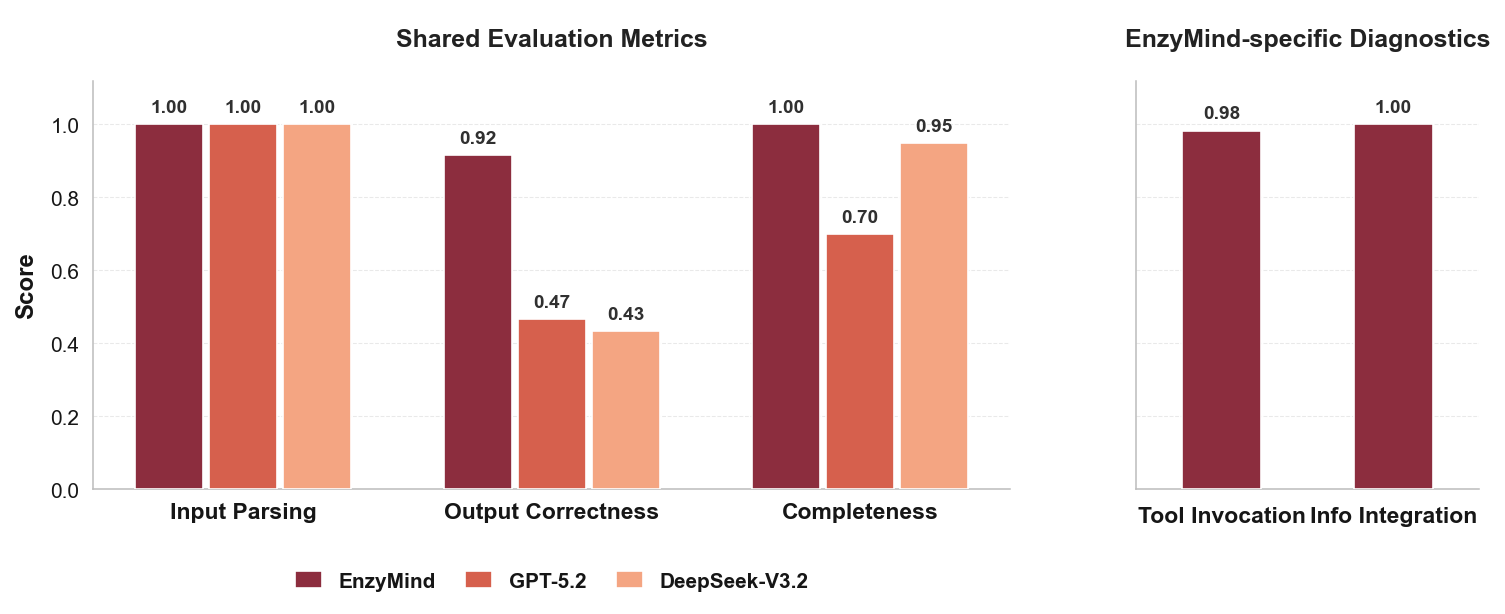

In [2]:

# =========================
# Data: Level 4
# =========================
methods = ["EnzyMind", "GPT-5.2", "DeepSeek-V3.2"]

shared_metrics = ["Input Parsing", "Output Correctness", "Completeness"]
shared_scores = {
    "EnzyMind":      [1.000, 0.917, 1.000],
    "GPT-5.2":       [1.000, 0.467, 0.700],
    "DeepSeek-V3.2": [1.000, 0.433, 0.950],
}

diag_metrics = ["Tool Invocation", "Info Integration"]
diag_scores  = [0.983, 1.000]

# =========================
# Style
# =========================
BG        = "#ffffff"
DARK      = "#000000"
LABEL_CLR = "#161616"
VALUE_CLR = "#303030"

method_colors = {
    "EnzyMind":      "#8c2d3e",
    "GPT-5.2":       "#d6604d",
    "DeepSeek-V3.2": "#f4a582",
}
diag_color = "#8c2d3e"

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica Neue", "DejaVu Sans"],
    "mathtext.fontset": "stixsans",
    "axes.unicode_minus": False,
})

sns.set_theme(
    style="white",
    font_scale=1.0,
    rc={
        "figure.facecolor": BG,
        "axes.facecolor": BG,
        "axes.edgecolor": "#cccccc",
        "figure.dpi": 150,
    },
)

# =========================
# Layout
# =========================
fig = plt.figure(figsize=(10.5, 4.8), facecolor=BG, constrained_layout=False)
gs = fig.add_gridspec(
    nrows=2, ncols=2,
    height_ratios=[0.14, 1],
    width_ratios=[3.2, 1.2],
    hspace=0.04,
    wspace=0.20,
    left=0.09, right=0.97,
    top=0.90, bottom=0.24,
)

ax_head1 = fig.add_subplot(gs[0, 0])
ax_head2 = fig.add_subplot(gs[0, 1])
ax1 = fig.add_subplot(gs[1, 0])
ax2 = fig.add_subplot(gs[1, 1])

# =========================
# Header bands
# =========================
header_specs = [
    (ax_head1, "Shared Evaluation Metrics"),
    (ax_head2, "EnzyMind-specific Diagnostics"),
]
for ax_h, label in header_specs:
    ax_h.set_xlim(0, 1)
    ax_h.set_ylim(0, 1)
    ax_h.text(
        0.5, 0.55, label,
        ha="center", va="center",
        fontsize=12, fontweight="bold", color="#222222",
        transform=ax_h.transAxes,
    )
    ax_h.axis("off")

# =========================
# Panel (a): Grouped bar chart — Shared metrics
# =========================
x = np.arange(len(shared_metrics))
bar_width = 0.24
main_bar_width = bar_width * 0.92

for i, method in enumerate(methods):
    offset = (i - 1) * bar_width
    bars = ax1.bar(
        x + offset,
        shared_scores[method],
        width=main_bar_width,
        label=method,
        color=method_colors[method],
        edgecolor="white",
        linewidth=0.8,
        zorder=3,
    )
    for bar, val in zip(bars, shared_scores[method]):
        ax1.text(
            bar.get_x() + bar.get_width() / 2,
            min(val + 0.022, 1.035),
            f"{val:.2f}",
            ha="center", va="bottom",
            fontsize=9.2, color=VALUE_CLR,
            fontweight="semibold",
        )

ax1.set_facecolor(BG)
ax1.set_xticks(x)
ax1.set_xticklabels(shared_metrics, fontsize=11, fontweight="bold", color=LABEL_CLR)
ax1.set_ylim(0, 1.12)
ax1.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax1.set_ylabel("Score", fontsize=11.5, color=LABEL_CLR, fontweight="bold", labelpad=6)
ax1.tick_params(axis="y", labelsize=10, colors=LABEL_CLR, length=3.2, width=0.7)
ax1.tick_params(axis="x", length=0, pad=6)

ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.spines["left"].set_color("#bdbdbd")
ax1.spines["bottom"].set_color("#bdbdbd")
ax1.spines["left"].set_linewidth(0.75)
ax1.spines["bottom"].set_linewidth(0.75)

ax1.grid(axis="y", linestyle="--", alpha=0.25, color="#aaaaaa", linewidth=0.5, zorder=0)
ax1.set_axisbelow(True)

legend = ax1.legend(
    frameon=False,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=3,
    fontsize=10,
    handlelength=1.3,
    handleheight=0.85,
    columnspacing=1.4,
    borderaxespad=0.0,
)
for text in legend.get_texts():
    text.set_color(LABEL_CLR)
    text.set_fontweight("semibold")

# =========================
# Panel (b): EnzyMind-only diagnostics
# =========================
x2 = np.array([0.0, 0.48])
bars2 = ax2.bar(
    x2,
    diag_scores,
    width=main_bar_width,
    color=diag_color,
    edgecolor="white",
    linewidth=0.8,
    zorder=3,
)

for bar, val in zip(bars2, diag_scores):
    ax2.text(
        bar.get_x() + bar.get_width() / 2,
        min(val + 0.022, 1.035),
        f"{val:.2f}",
        ha="center", va="bottom",
        fontsize=9.2, color=VALUE_CLR,
        fontweight="semibold",
    )

ax2.set_facecolor(BG)
ax2.set_xticks(x2)
ax2.set_xticklabels(diag_metrics, rotation=0, ha="center", fontsize=11, fontweight="bold", color=LABEL_CLR)
ax2.set_xlim(-0.24, 0.72)
ax2.set_ylim(0, 1.12)
ax2.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax2.set_yticklabels([])
ax2.tick_params(axis="y", labelsize=10, colors=LABEL_CLR, length=3.2, width=0.7)
ax2.tick_params(axis="x", length=0, pad=8)

ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.spines["left"].set_color("#bdbdbd")
ax2.spines["bottom"].set_color("#bdbdbd")
ax2.spines["left"].set_linewidth(0.75)
ax2.spines["bottom"].set_linewidth(0.75)

ax2.grid(axis="y", linestyle="--", alpha=0.25, color="#aaaaaa", linewidth=0.5, zorder=0)
ax2.set_axisbelow(True)

plt.savefig("level4_dual_panel_barplot.png", dpi=300, bbox_inches="tight", facecolor=BG)
plt.savefig("level4_dual_panel_barplot.svg", bbox_inches="tight", facecolor=BG)
plt.show()
